# SafeStep · 1 — Windows, labels, 345 features
`50 Hz trials` → `3 s windows (0.5 s step)` → `fall-phase labels` → `345 features (279 phone-ready)` → Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, sys, json, time
BASE = '/content/drive/MyDrive/Daffodil Robo Tech Olympiad'
PROJ = f'{BASE}/SafeStep'
D = {k: f'{PROJ}/{k}' for k in ['data', 'artifacts', 'figures', 'models', 'code']}
for p in D.values(): os.makedirs(p, exist_ok=True)

In [3]:
%%writefile "/content/drive/MyDrive/Daffodil Robo Tech Olympiad/SafeStep/code/safestep_core.py"
# safestep_core.py — shared by every notebook AND the Streamlit app.
# The same code turns SisFall trials and live phone recordings into features.
import numpy as np
from scipy import signal as sps
from scipy import stats as spst

FS = 50              # Hz after downsampling
WIN = 150            # 3.0 s window
STRIDE = 25          # 0.5 s step
G = 9.80665

INVARIANT_SIGNALS = ['svm', 'dyn', 'vert', 'horiz', 'gyro', 'jerk', 'tilt']
DEVICE_AXES = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']
STAT_NAMES = ['mean', 'std', 'min', 'max', 'range', 'p05', 'median', 'iqr', 'p95',
              'skew', 'kurt', 'rms', 'mad', 'mcr', 'npeaks', 'argmax', 'argmin']
SPEC_NAMES = ['domfreq', 'domratio', 'centroid', 'spread', 'entropy', 'rolloff',
              'band_0_1', 'band_1_3', 'band_3_5', 'band_5_8', 'band_8_12', 'band_12_25']
TEMP_NAMES = ['ac_lag05', 'ac_lag1', 'ac_peak', 'ac_peak_lag', 'd1_mean', 'd2_mean']
DOMAIN_NAMES = ['peak_svm', 'peak_pos', 'prepeak_min', 'freefall_time', 'freefall_longest',
                'impact_ratio', 'peak_drop', 'post_std', 'post_mean', 'post_gyro_mean',
                'pre_std', 'post_pre_std_ratio', 'tilt_end', 'tilt_max', 'tilt_rate_max',
                'vvel_min', 'vvel_max', 'vvel_range', 'still_frac', 'still_longest',
                'jerk_peak', 'jerk_peak_pos', 'gyro_peak', 'gyro_lag', 'highg_time',
                'hv_energy_ratio', 'n_impacts', 't_min_to_max']
XCORR_PAIRS = [('svm', 'gyro'), ('vert', 'horiz'), ('dyn', 'gyro'),
               ('jerk', 'gyro'), ('vert', 'gyro'), ('tilt', 'gyro')]
DEVICE_STATS = ['mean', 'std', 'min', 'max', 'skew', 'kurt', 'rms', 'p05', 'p95', 'domfreq']
DEVICE_PAIRS = [('ax', 'ay'), ('ax', 'az'), ('ay', 'az'), ('gx', 'gy'), ('gx', 'gz'), ('gy', 'gz')]


# ---------------------------------------------------------------- signals
def lowpass(x, fc, fs=FS, order=4):
    b, a = sps.butter(order, fc / (fs / 2), btype='low')
    padlen = min(3 * max(len(a), len(b)), x.shape[0] - 1)
    return sps.filtfilt(b, a, x, axis=0, padlen=padlen)


def resample_uniform(t_sec, X, fs=FS):
    """Irregular phone timestamps -> uniform fs grid (linear interpolation)."""
    t_sec = np.asarray(t_sec, float)
    order = np.argsort(t_sec)
    t_sec, X = t_sec[order], np.asarray(X, float)[order]
    grid = np.arange(t_sec[0], t_sec[-1], 1.0 / fs)
    return grid, np.column_stack([np.interp(grid, t_sec, X[:, i]) for i in range(X.shape[1])])


def derive_signals(acc_g, gyro_dps, fs=FS):
    """acc in g (T,3), gyro in deg/s (T,3) -> per-sample signals (orientation-invariant + device axes)."""
    acc = np.asarray(acc_g, np.float64)
    gyr = np.asarray(gyro_dps, np.float64)
    grav = lowpass(acc, 0.3, fs)
    gn = np.linalg.norm(grav, axis=1, keepdims=True)
    gu = grav / np.maximum(gn, 1e-6)
    dyn = acc - grav
    vert = np.sum(dyn * gu, axis=1)
    svm = np.linalg.norm(acc, axis=1)
    return {
        'svm': svm,
        'dyn': np.linalg.norm(dyn, axis=1),
        'vert': vert,
        'horiz': np.linalg.norm(dyn - vert[:, None] * gu, axis=1),
        'gyro': np.linalg.norm(gyr, axis=1),
        'jerk': np.gradient(svm) * fs,
        'gu': gu,
        'ax': acc[:, 0], 'ay': acc[:, 1], 'az': acc[:, 2],
        'gx': gyr[:, 0], 'gy': gyr[:, 1], 'gz': gyr[:, 2],
    }


def window_signals(sig, starts, W=WIN):
    """Per-sample signals -> dict of (N, W) windows, plus window-relative tilt (deg)."""
    idx = np.asarray(starts)[:, None] + np.arange(W)[None, :]
    out = {k: sig[k][idx].astype(np.float32) for k in sig if k != 'gu'}
    gu = sig['gu'][idx]                               # (N, W, 3)
    cosang = np.clip(np.sum(gu * gu[:, :1, :], axis=2), -1, 1)
    out['tilt'] = np.degrees(np.arccos(cosang)).astype(np.float32)
    return out


def trial_windows(acc_g, gyro_dps, starts, fs=FS):
    return window_signals(derive_signals(acc_g, gyro_dps, fs), starts)


# ---------------------------------------------------------------- feature blocks
def _rowcorr(A, B):
    A = A - A.mean(1, keepdims=True)
    B = B - B.mean(1, keepdims=True)
    den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
    return np.where(den > 1e-12, (A * B).sum(1) / np.maximum(den, 1e-12), 0.0)


def _longest_run(B):
    cur = np.zeros(B.shape[0])
    best = np.zeros(B.shape[0])
    for t in range(B.shape[1]):
        cur = (cur + 1) * B[:, t]
        best = np.maximum(best, cur)
    return best


def _masked_mean_std(X, M):
    n = M.sum(1)
    s = np.where(M, X, 0).sum(1)
    mean = np.where(n > 0, s / np.maximum(n, 1), 0)
    var = np.where(M, (X - mean[:, None]) ** 2, 0).sum(1) / np.maximum(n, 1)
    return mean, np.sqrt(var)


def _stats(X):
    W = X.shape[1]
    mean, std = X.mean(1), X.std(1)
    mn, mx = X.min(1), X.max(1)
    q = np.percentile(X, [5, 25, 50, 75, 95], axis=1)
    c = X - mean[:, None]
    mid = X[:, 1:-1]
    peaks = (mid > X[:, :-2]) & (mid >= X[:, 2:]) & (mid > (mean + std)[:, None])
    with np.errstate(all='ignore'):
        sk = spst.skew(X, axis=1)
        ku = spst.kurtosis(X, axis=1)
    return [mean, std, mn, mx, mx - mn, q[0], q[2], q[3] - q[1], q[4], sk, ku,
            np.sqrt((X ** 2).mean(1)), np.abs(c).mean(1),
            (np.diff(np.sign(c), axis=1) != 0).mean(1), peaks.sum(1),
            X.argmax(1) / (W - 1), X.argmin(1) / (W - 1)]


def _spectral(X, fs=FS):
    W = X.shape[1]
    Xc = (X - X.mean(1, keepdims=True)) * np.hanning(W)
    P = (np.abs(np.fft.rfft(Xc, axis=1)) ** 2)[:, 1:]
    fr = np.fft.rfftfreq(W, 1 / fs)[1:]
    tot = P.sum(1) + 1e-12
    pn = P / tot[:, None]
    cent = (pn * fr).sum(1)
    spread = np.sqrt((pn * (fr[None, :] - cent[:, None]) ** 2).sum(1))
    ent = -(pn * np.log(pn + 1e-12)).sum(1) / np.log(len(fr))
    roll = fr[np.argmax(np.cumsum(pn, 1) >= 0.85, axis=1)]
    bands = [pn[:, (fr >= lo) & (fr < hi)].sum(1)
             for lo, hi in [(0, 1), (1, 3), (3, 5), (5, 8), (8, 12), (12, 25.01)]]
    return [fr[P.argmax(1)], P.max(1) / tot, cent, spread, ent, roll] + bands


def _temporal(X, fs=FS):
    W = X.shape[1]
    Xc = X - X.mean(1, keepdims=True)
    F = np.fft.rfft(Xc, n=2 * W, axis=1)
    ac = np.fft.irfft(F * np.conj(F), axis=1)[:, :W]
    ac = np.where(ac[:, :1] > 1e-12, ac / np.maximum(ac[:, :1], 1e-12), 0)
    lo, hi = int(0.3 * fs), int(2.0 * fs)
    seg = ac[:, lo:hi]
    return [ac[:, int(0.5 * fs)], ac[:, int(1.0 * fs)], seg.max(1), (seg.argmax(1) + lo) / fs,
            np.abs(np.diff(X, axis=1)).mean(1) * fs, np.abs(np.diff(X, 2, axis=1)).mean(1) * fs * fs]


def _domain(S, fs=FS):
    m, gy, ti = S['svm'], S['gyro'], S['tilt']
    N, W = m.shape
    ar = np.arange(W)[None, :]
    pk = m.argmax(1)
    peak = m.max(1)
    pre1 = (ar < pk[:, None]) & (ar >= (pk - fs)[:, None])
    m_pre = np.where(pre1, m, np.inf)
    premin = np.where(pre1.any(1), m_pre.min(1), peak)
    t_min2max = np.where(pre1.any(1), (pk - m_pre.argmin(1)) / fs, 0)
    post = ar > (pk + fs // 2)[:, None]
    before = ar < pk[:, None]
    post_mean, post_std = _masked_mean_std(m, post)
    pg_mean, _ = _masked_mean_std(gy, post)
    _, pre_std = _masked_mean_std(m, before)
    ff = m < 0.6
    vvel = np.cumsum(S['vert'], axis=1) * G / fs
    still = (gy < 10) & (S['dyn'] < 0.05)
    jk = np.abs(S['jerk'])
    mid = m[:, 1:-1]
    impacts = (mid > m[:, :-2]) & (mid >= m[:, 2:]) & (mid > 1.8)
    hv = (S['horiz'] ** 2).sum(1) / ((S['vert'] ** 2).sum(1) + 1e-9)
    return [peak, pk / (W - 1), premin, ff.sum(1) / fs, _longest_run(ff) / fs,
            peak / (premin + 1e-3), peak - premin, post_std, post_mean, pg_mean,
            pre_std, post_std / (pre_std + 1e-3), ti[:, -1], ti.max(1),
            np.abs(np.diff(ti, axis=1)).max(1) * fs,
            vvel.min(1), vvel.max(1), vvel.max(1) - vvel.min(1),
            still.mean(1), _longest_run(still) / fs,
            jk.max(1), jk.argmax(1) / (W - 1), gy.max(1), (gy.argmax(1) - pk) / fs,
            (m > 2.0).sum(1) / fs, hv, impacts.sum(1), t_min2max]


# ---------------------------------------------------------------- public API
def feature_catalog():
    rows = []
    for s in INVARIANT_SIGNALS:
        rows += [(f'{s}__{n}', 'statistical', s, 'invariant') for n in STAT_NAMES]
        rows += [(f'{s}__{n}', 'spectral', s, 'invariant') for n in SPEC_NAMES]
        rows += [(f'{s}__{n}', 'temporal', s, 'invariant') for n in TEMP_NAMES]
    rows += [(f'fall__{n}', 'fall_dynamics', 'multi', 'invariant') for n in DOMAIN_NAMES]
    rows += [(f'xcorr__{a}_{b}', 'cross_signal', f'{a}+{b}', 'invariant') for a, b in XCORR_PAIRS]
    for ax in DEVICE_AXES:
        rows += [(f'{ax}__{n}', 'device_axis', ax, 'device') for n in DEVICE_STATS]
    rows += [(f'axcorr__{a}_{b}', 'device_axis', f'{a}+{b}', 'device') for a, b in DEVICE_PAIRS]
    return rows


FEATURE_NAMES = [r[0] for r in feature_catalog()]
INVARIANT_FEATURES = [r[0] for r in feature_catalog() if r[3] == 'invariant']


def extract_features(S, fs=FS):
    """S: dict of (N, W) windows from window_signals -> (N, 345) float32."""
    cols = []
    for s in INVARIANT_SIGNALS:
        X = S[s].astype(np.float64)
        cols += _stats(X) + _spectral(X, fs) + _temporal(X, fs)
    cols += _domain({k: S[k].astype(np.float64) for k in S}, fs)
    cols += [_rowcorr(S[a].astype(np.float64), S[b].astype(np.float64)) for a, b in XCORR_PAIRS]
    for ax in DEVICE_AXES:
        X = S[ax].astype(np.float64)
        st = _stats(X)
        cols += [st[0], st[1], st[2], st[3], st[9], st[10], st[11], st[5], st[8], _spectral(X, fs)[0]]
    cols += [_rowcorr(S[a].astype(np.float64), S[b].astype(np.float64)) for a, b in DEVICE_PAIRS]
    F = np.column_stack(cols).astype(np.float32)
    return np.nan_to_num(F, nan=0.0, posinf=0.0, neginf=0.0)

Writing /content/drive/MyDrive/Daffodil Robo Tech Olympiad/SafeStep/code/safestep_core.py


In [4]:
sys.path.insert(0, D['code'])
import importlib, safestep_core as core; importlib.reload(core)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
def save_fig(name): plt.savefig(f"{D['figures']}/{name}.png", dpi=300, bbox_inches='tight')

signals = np.load(f"{D['data']}/signals_50hz.npz")['signals']
meta = pd.read_parquet(f"{D['data']}/trials_meta.parquet")
FS, W, STEP = core.FS, core.WIN, core.STRIDE
EDGE = FS // 2                      # impact must sit ≥0.5 s inside the window
print(meta.shape, signals.shape, '| features:', len(core.FEATURE_NAMES),
      '| phone-ready:', len(core.INVARIANT_FEATURES))

(4505, 19) (3964862, 9) | features: 345 | phone-ready: 279


In [5]:
def phase_of(start, impact):
    pos = impact - start
    if EDGE <= pos < W - EDGE: return 'impact'
    if pos >= W:               return 'pre_fall'
    if pos < 0:                return 'post_fall'
    return 'edge'

win_rows, feats, buf, buf_n = [], [], [], 0
CHUNK = 8000
def flush():
    global buf, buf_n
    if not buf: return
    S = {k: np.concatenate([b[k] for b in buf]) for k in buf[0]}
    feats.append(core.extract_features(S)); buf, buf_n = [], 0

t0 = time.time()
for r in tqdm(meta.itertuples(), total=len(meta), desc='windows+features'):
    x = signals[r.offset:r.offset + r.n_samples]
    if len(x) < W: continue
    starts = np.arange(0, len(x) - W + 1, STEP)
    buf.append(core.trial_windows(x[:, 0:3], x[:, 3:6], starts)); buf_n += len(starts)
    for s in starts:
        if r.type == 'Fall':
            ph = phase_of(s, r.peak_idx)
            t_rel = (s + W - r.peak_idx) / FS          # window end relative to impact (s)
        else:
            ph, t_rel = 'adl', np.nan
        win_rows.append((r.trial_id, int(s), ph, t_rel))
    if buf_n >= CHUNK: flush()
flush()
X = np.concatenate(feats)
print(f'{X.shape} in {time.time()-t0:.0f}s')

windows+features:   0%|          | 0/4505 [00:00<?, ?it/s]

(136051, 345) in 49s


In [6]:
wm = pd.DataFrame(win_rows, columns=['trial_id', 'start', 'phase', 't_end_rel_impact'])
wm = wm.merge(meta[['trial_id', 'code', 'subject', 'age_group', 'type', 'name', 'group',
                    'direction', 'context', 'split']], on='trial_id', how='left')
wm.insert(0, 'win_id', np.arange(len(wm)))
wm['start_s'] = wm.start / FS
wm['y_fall'] = np.select([wm.phase == 'impact', wm.phase == 'adl'], [1, 0], -1)           # -1 = ignored
wm['y_activity'] = np.select([wm.phase == 'adl', wm.phase == 'impact', wm.phase == 'post_fall'],
                             [wm.group, 'Fall', 'Lying after fall'], 'ignore')
wm['y_direction'] = np.where(wm.phase == 'impact', wm.direction, 'ignore')
wm['y_context']   = np.where(wm.phase == 'impact', wm.context, 'ignore')
wm['y_preimpact'] = np.select([(wm.type == 'Fall') & wm.t_end_rel_impact.between(-0.6, -0.05),
                               wm.phase == 'adl'], [1, 0], -1)                         # falling, before impact
assert len(wm) == len(X)
pd.crosstab(wm.phase, wm.split)

split,test,train,val
phase,,,
adl,23889,50065,17153
edge,897,2093,599
impact,1800,4192,1200
post_fall,5203,11409,3775
pre_fall,3349,8501,1926


In [7]:
F = pd.DataFrame(X, columns=core.FEATURE_NAMES)
qa = {
 'windows': len(F), 'features': F.shape[1],
 'non-finite values': int((~np.isfinite(F.values)).sum()),
 'constant features': int((F.std() == 0).sum()),
 'fall windows (train/val/test)': tuple(int(((wm.y_fall == 1) & (wm.split == s)).sum()) for s in ['train', 'val', 'test']),
 'ADL windows (train/val/test)':  tuple(int(((wm.y_fall == 0) & (wm.split == s)).sum()) for s in ['train', 'val', 'test']),
}
for k, v in qa.items(): print(f'{k:32s} {v}')
cat = pd.DataFrame(core.feature_catalog(), columns=['feature', 'group', 'signal', 'frame'])
cat.groupby(['group', 'frame']).size().unstack(fill_value=0)

windows                          136051
features                         345
non-finite values                0
constant features                1
fall windows (train/val/test)    (4192, 1200, 1800)
ADL windows (train/val/test)     (50065, 17153, 23889)


frame,device,invariant
group,,
cross_signal,0,6
device_axis,66,0
fall_dynamics,0,28
spectral,0,84
statistical,0,119
temporal,0,42


## Feature views

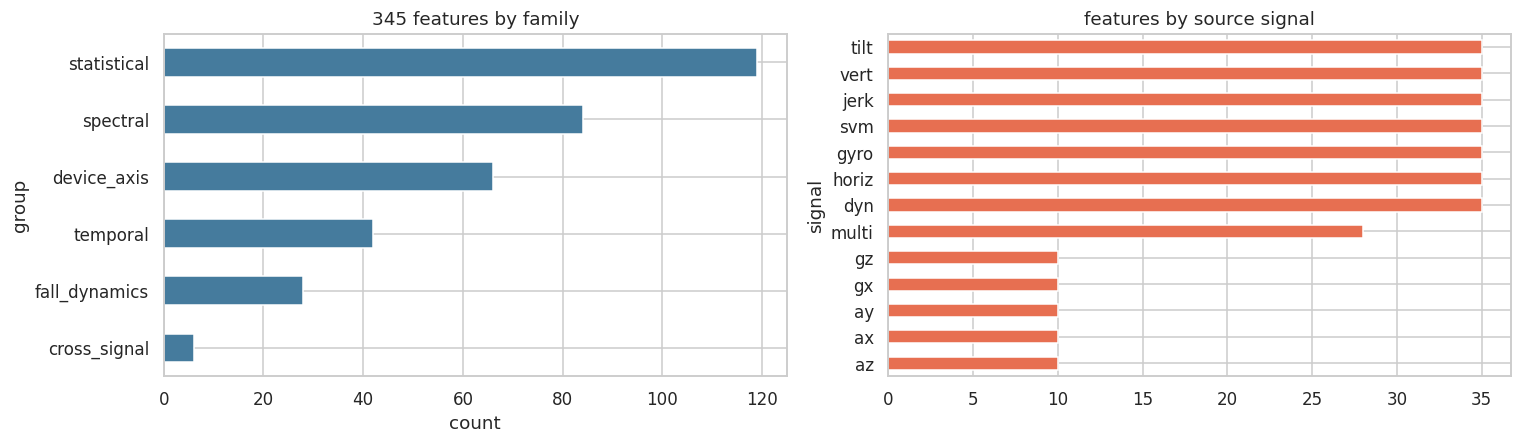

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
cat.groupby('group').size().sort_values().plot.barh(ax=ax[0], color='#457b9d')
ax[0].set_title(f'{len(cat)} features by family'); ax[0].set_xlabel('count')
cat.groupby('signal').size().sort_values().tail(13).plot.barh(ax=ax[1], color='#e76f51')
ax[1].set_title('features by source signal'); plt.tight_layout(); save_fig('10_feature_families'); plt.show()

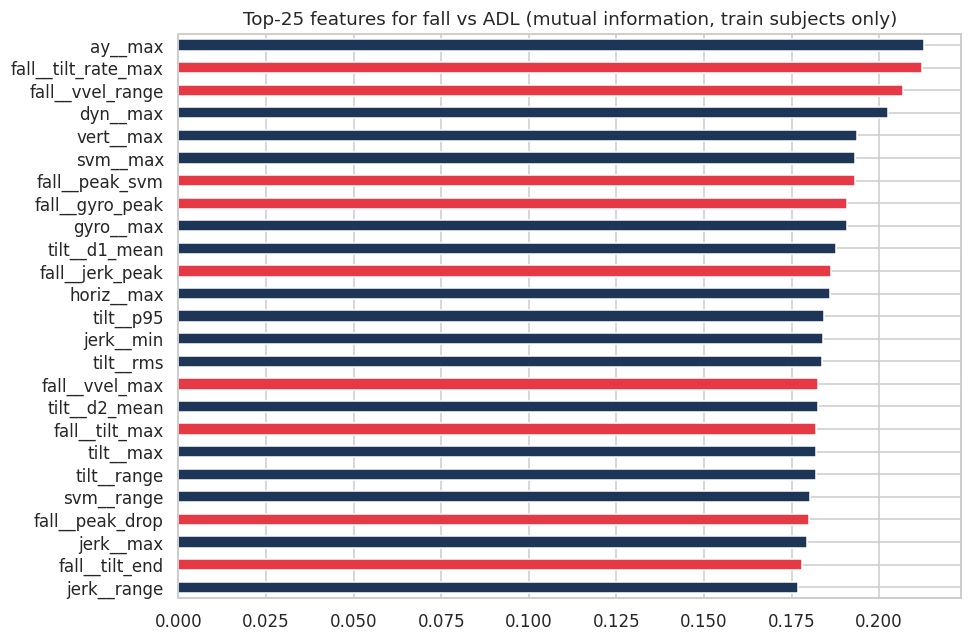

In [9]:
from sklearn.feature_selection import mutual_info_classif
tr = (wm.split == 'train') & (wm.y_fall >= 0)
idx = np.random.default_rng(42).choice(np.where(tr)[0], size=min(30000, tr.sum()), replace=False)
mi = pd.Series(mutual_info_classif(F.values[idx], wm.y_fall.values[idx], random_state=42),
               index=F.columns).sort_values(ascending=False)
plt.figure(figsize=(9, 6))
mi.head(25)[::-1].plot.barh(color=['#e63946' if c.startswith('fall__') else '#1d3557' for c in mi.head(25).index[::-1]])
plt.title('Top-25 features for fall vs ADL (mutual information, train subjects only)')
plt.tight_layout(); save_fig('11_top_features_mi'); plt.show()

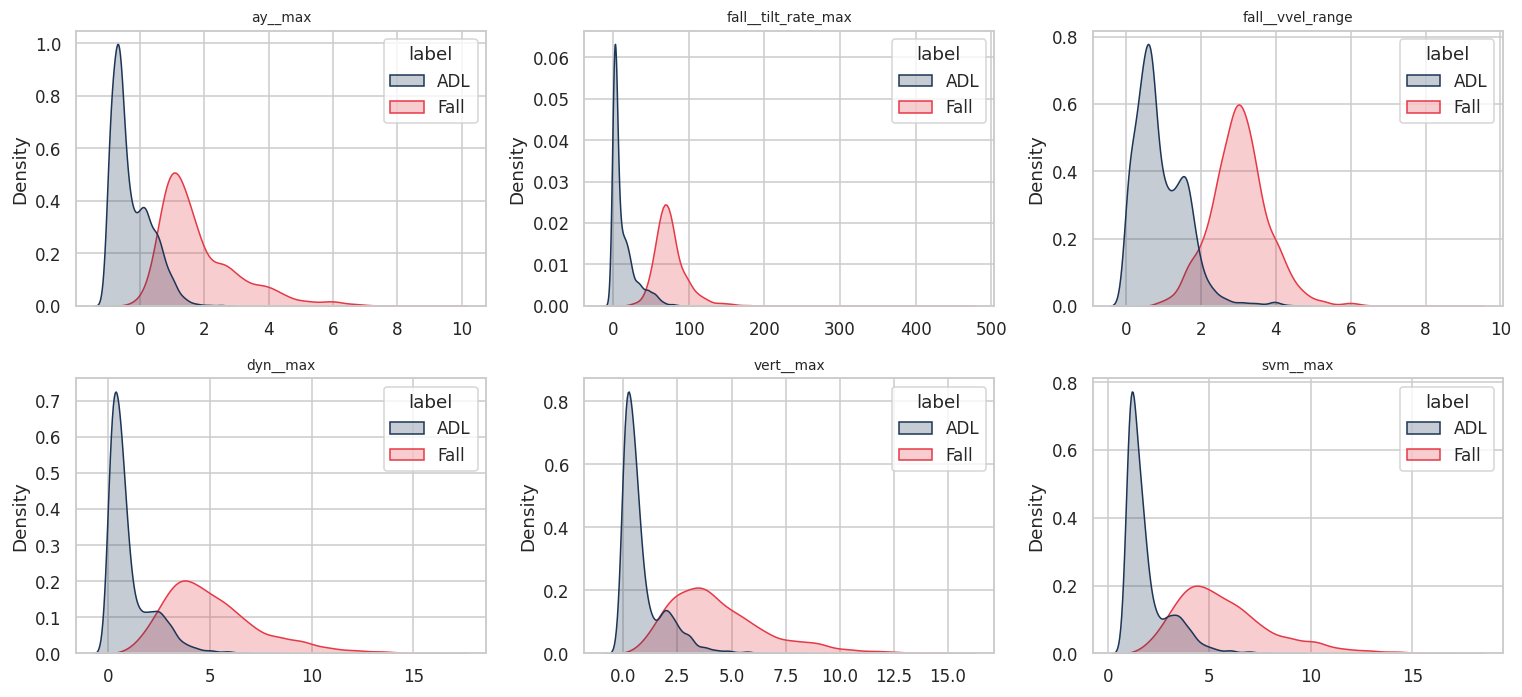

In [10]:
top = mi.index[:6]
sub = F.loc[wm.y_fall >= 0, top].copy(); sub['label'] = np.where(wm.y_fall[wm.y_fall >= 0] == 1, 'Fall', 'ADL')
sub = pd.concat([g.sample(min(len(g), 3000), random_state=42) for _, g in sub.groupby('label')])
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
for ax, f in zip(axes.ravel(), top):
    sns.kdeplot(data=sub, x=f, hue='label', fill=True, common_norm=False, ax=ax, warn_singular=False,
                palette={'Fall': '#e63946', 'ADL': '#1d3557'})
    ax.set_title(f, fontsize=9); ax.set_xlabel('')
plt.tight_layout(); save_fig('12_top_feature_distributions'); plt.show()

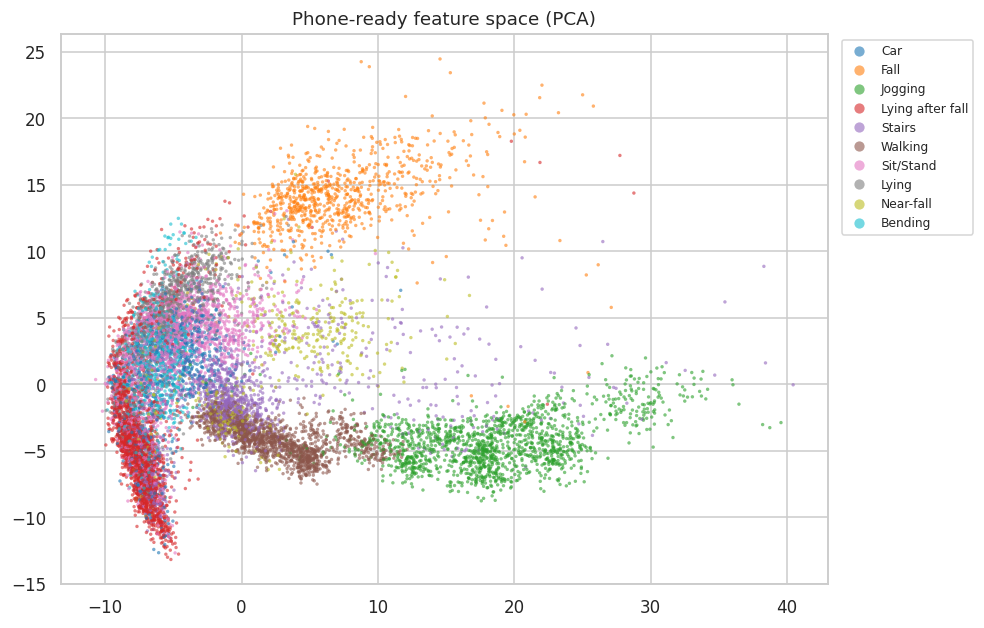

In [11]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
m = (wm.y_activity != 'ignore') & (wm.split == 'train')
ii = np.random.default_rng(1).choice(np.where(m)[0], size=min(12000, m.sum()), replace=False)
Z = PCA(2, random_state=42).fit_transform(StandardScaler().fit_transform(F.values[ii][:, :len(core.INVARIANT_FEATURES)]))
plt.figure(figsize=(9, 6.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=wm.y_activity.values[ii], s=5, alpha=0.6, linewidth=0, palette='tab10')
plt.legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.title('Phone-ready feature space (PCA)'); save_fig('13_feature_space_pca'); plt.show()

In [12]:
F.insert(0, 'win_id', wm.win_id.values)
F.to_parquet(f"{D['data']}/features_345.parquet", index=False)
wm.to_parquet(f"{D['data']}/windows_meta.parquet", index=False)
cat.to_csv(f"{D['artifacts']}/feature_catalog.csv", index=False)
mi.rename('mutual_info').to_csv(f"{D['artifacts']}/feature_mi_fall.csv")
json.dump({'fs': FS, 'window': W, 'stride': STEP, 'edge': EDGE, 'n_features': len(core.FEATURE_NAMES),
           'n_invariant': len(core.INVARIANT_FEATURES)}, open(f"{D['artifacts']}/window_config.json", 'w'), indent=2)
for f in ['features_345.parquet', 'windows_meta.parquet']:
    print(f, f"{os.path.getsize(D['data'] + '/' + f)/1e6:.0f} MB")

features_345.parquet 218 MB
windows_meta.parquet 1 MB
